In [114]:
suppressMessages(library(ComplexHeatmap))
suppressMessages(library(DESeq2))
suppressMessages(library(ggplot2))
suppressMessages(library(cowplot))
suppressMessages(library(dplyr))
suppressMessages(library(apeglm))
suppressMessages(library(ggrepel))
suppressMessages(library(circlize))

In [115]:
in_dir <- "../../results/09_analysis_podocyte_niche/09_create_bulk"
out_dir <- "../../results/09_analysis_podocyte_niche/12_plot_heatmap"

# create output directory if it doesn't exist
if (!dir.exists(out_dir)) {
   dir.create(out_dir, recursive = TRUE)
}

In [116]:
df1 <- t(read.csv(glue::glue("{in_dir}/Periglomerular_counts_bulk.csv"), row.names = 1, check.names = FALSE))
df1 <- df1[, c("sample_15837", 
                "sample_15852", 
                "sample_16512", 
                "sample_21022", 
                "sample_8262")]

colnames(df1) <- c("Periglomerular_1", 
                   "Periglomerular_2", 
                   "Periglomerular_3", 
                   "Periglomerular_4", 
                   "Periglomerular_5")

df2 <- t(read.csv(glue::glue("{in_dir}/Glomerular_counts_bulk.csv"), row.names = 1, check.names = FALSE))
df2 <- df2[, c("sample_15837", 
                "sample_15852", 
                "sample_16512", 
                "sample_21022", 
                "sample_8262")]

colnames(df2) <- c("Glomerular_1", 
                   "Glomerular_2", 
                   "Glomerular_3", 
                   "Glomerular_4", 
                   "Glomerular_5")

df3 <- t(read.csv(glue::glue("{in_dir}/Tubulointerstitial_counts_bulk.csv"), row.names = 1, check.names = FALSE))
df3 <- df3[, c("sample_15837", 
                "sample_15852", 
                "sample_16512", 
                "sample_21022", 
                "sample_8262")]

colnames(df3) <- c("Tubulointerstitial_1", 
                   "Tubulointerstitial_2", 
                   "Tubulointerstitial_3", 
                   "Tubulointerstitial_4", 
                   "Tubulointerstitial_5")

In [117]:
df <- cbind(df1, df2, df3)

In [118]:
head(df)

,Periglomerular_1,Periglomerular_2,Periglomerular_3,Periglomerular_4,Periglomerular_5,Glomerular_1,Glomerular_2,Glomerular_3,Glomerular_4,Glomerular_5,Tubulointerstitial_1,Tubulointerstitial_2,Tubulointerstitial_3,Tubulointerstitial_4,Tubulointerstitial_5
SAMD11,11,59,34,88,4,4,16,20,23,6,98,185,118,462,14
NOC2L,17,47,57,86,3,2,8,22,24,0,172,202,295,508,49
KLHL17,10,27,34,25,3,3,6,5,3,4,67,96,95,173,26
PLEKHN1,3,15,12,16,9,1,2,2,1,3,49,71,46,127,22
PERM1,0,5,9,0,2,0,0,0,1,0,12,40,19,26,9
HES4,35,79,79,67,30,8,23,25,15,12,228,257,279,579,125


In [119]:
df_meta <- data.frame(
  sample = colnames(df),
  group = c(rep("Periglomerular", 5), 
  rep("Glomerular", 5), 
  rep("Tubulointerstitial", 5))
)

In [120]:
head(df_meta)

,sample,group
,<chr>,<chr>
1,Periglomerular_1,Periglomerular
2,Periglomerular_2,Periglomerular
3,Periglomerular_3,Periglomerular
4,Periglomerular_4,Periglomerular
5,Periglomerular_5,Periglomerular
6,Glomerular_1,Glomerular


In [121]:
dds <- DESeqDataSetFromMatrix(countData = df,
colData = df_meta,
design = ~ group)

converting counts to integer mode

Warning message in DESeqDataSet(se, design = design, ignoreRank):
“some variables in design formula are characters, converting to factors”


In [122]:
keep <- rowSums(counts(dds) >= 10) >= 5
dds <- dds[keep,]

In [123]:
dds

class: DESeqDataSet 
dim: 15015 15 
metadata(1): version
assays(1): counts
rownames(15015): SAMD11 NOC2L ... KDM5D EIF1AY
rowData names(0):
colnames(15): Periglomerular_1 Periglomerular_2 ...
  Tubulointerstitial_4 Tubulointerstitial_5
colData names(2): sample group

In [124]:
dds <- DESeq(dds)

estimating size factors

estimating dispersions

gene-wise dispersion estimates

mean-dispersion relationship

final dispersion estimates

fitting model and testing



In [125]:
df_res1 <- results(dds, contrast = c("group", "Glomerular", "Periglomerular")) %>%
    as.data.frame()

df_res2 <- results(dds, contrast = c("group", "Periglomerular", "Tubulointerstitial")) %>%
    as.data.frame()

df_res3 <- results(dds, contrast = c("group", "Glomerular", "Tubulointerstitial")) %>%
    as.data.frame()

write.csv(df_res1, glue::glue("{out_dir}/de_results_Glomerular_vs_Periglomerular.csv"))
write.csv(df_res2, glue::glue("{out_dir}/de_results_Periglomerular_vs_Tubulointerstitial.csv"))
write.csv(df_res3, glue::glue("{out_dir}/de_results_Glomerular_vs_Tubulointerstitial.csv"))

Warning message:
“Removed 2921 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 2921 rows containing missing values or values outside the scale range
(`geom_point()`).”


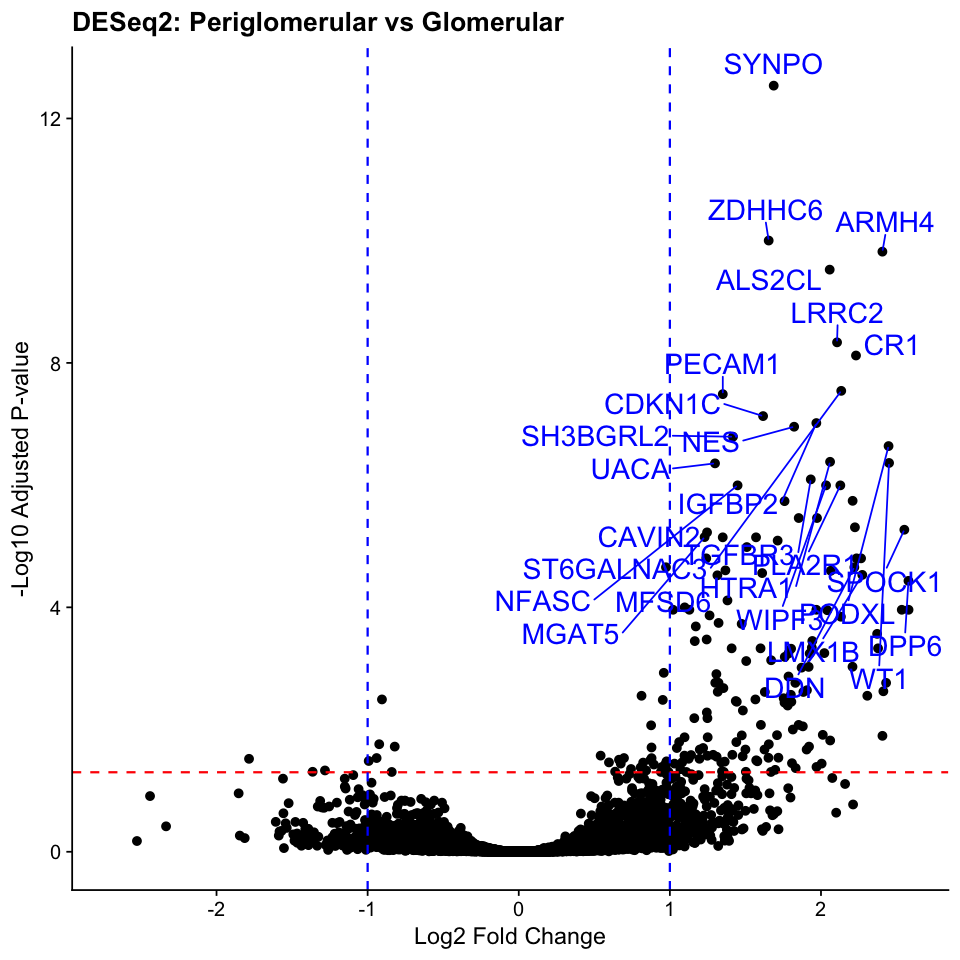

In [126]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text1 <- subset(df_res1, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res1, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text1, aes(label = rownames(df_text1)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: Periglomerular vs Glomerular") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_Periglomerular_vs_Glomerular.png"), 
width = 8, height = 8)

Warning message:
“Removed 5541 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 5541 rows containing missing values or values outside the scale range
(`geom_point()`).”


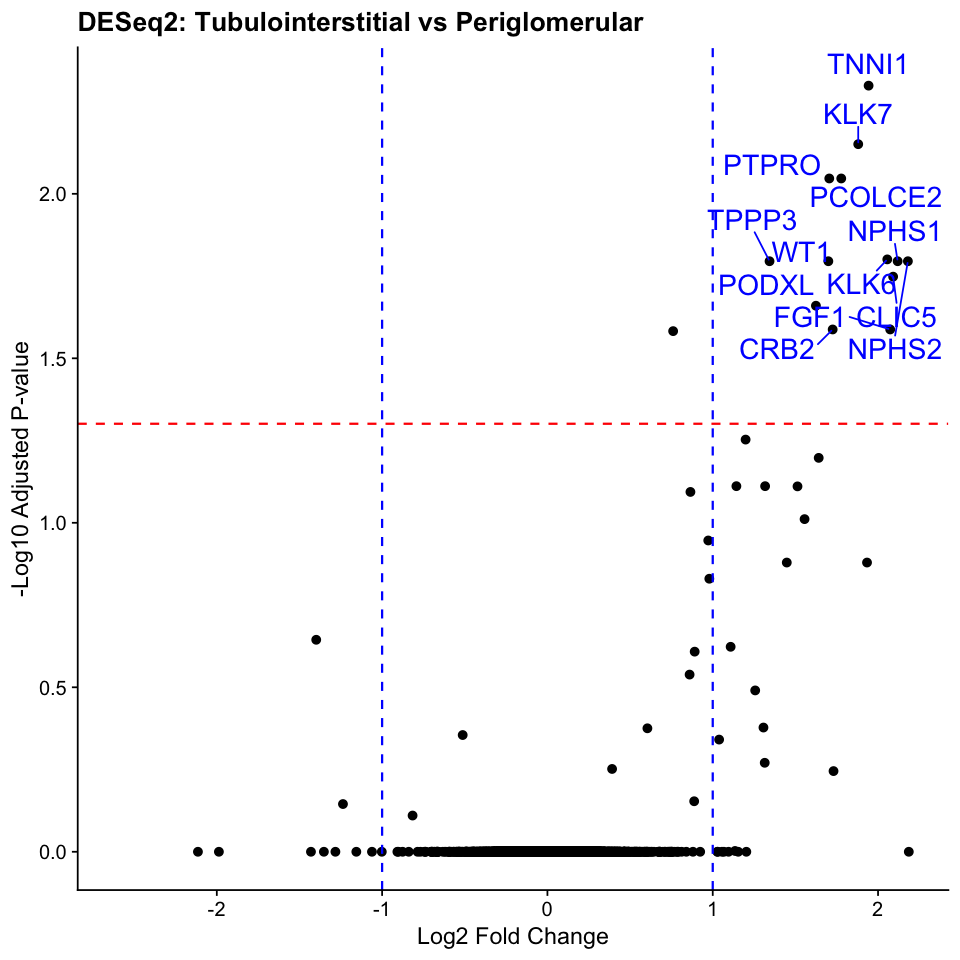

In [127]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text2 <- subset(df_res2, padj < 0.05 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res2, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text2, aes(label = rownames(df_text2)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: Tubulointerstitial vs Periglomerular") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_Tubulointerstitial_vs_Periglomerular.png"), 
width = 8, height = 8)

Warning message:
“Removed 2630 rows containing missing values or values outside the scale range
(`geom_point()`).”
Warning message:
“Removed 2630 rows containing missing values or values outside the scale range
(`geom_point()`).”


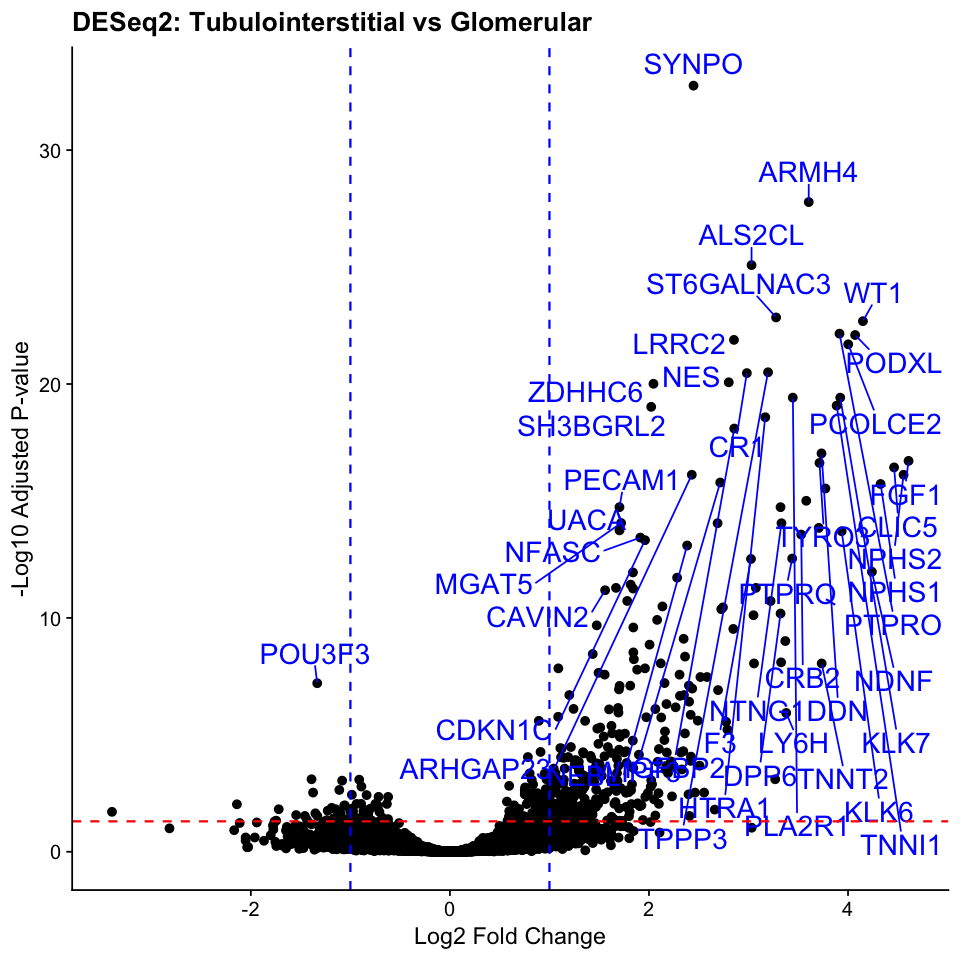

In [128]:
options(repr.plot.width = 8, repr.plot.height = 8)

df_text3 <- subset(df_res3, padj < 0.0001 & abs(log2FoldChange) > 1)

p <- ggplot(data = df_res3, aes(x = log2FoldChange, y = -log10(padj))) +
    geom_point() +
    geom_text_repel(data = df_text3, aes(label = rownames(df_text3)), vjust = -1, size = 6, color = "blue") +
    ggtitle("DESeq2: Tubulointerstitial vs Glomerular") +
    xlab("Log2 Fold Change") +
    ylab("-Log10 Adjusted P-value") +
    geom_hline(yintercept = -log10(0.05), linetype = "dashed", color = "red") +
    geom_vline(xintercept = c(-1, 1), linetype = "dashed", color = "blue") +
    theme_cowplot()

print(p)

ggsave(plot = p, 
filename = glue::glue("{out_dir}/volcano_plot_Tubulointerstitial_vs_Glomerular.png"), 
width = 8, height = 8)

In [129]:
# now let's make a heatmap of the top 20 DE genes in each comparison
df_sel1 <- subset(df_res1, padj < 0.05 & abs(log2FoldChange) > 1)
df_sel2 <- subset(df_res2, padj < 0.05 & abs(log2FoldChange) > 1)
df_sel3 <- subset(df_res3, padj < 0.05 & abs(log2FoldChange) > 1)

sel_gene1 <- rownames(df_sel1)
sel_gene2 <- rownames(df_sel2)
sel_gene3 <- rownames(df_sel3)

sel_genes <- unique(c(sel_gene1, sel_gene2, sel_gene3))

In [130]:
# get matrix of normalized counts for these genes
norm_counts <- counts(dds, normalized = TRUE)
norm_counts_sel <- norm_counts[sel_genes, ]
log_norm_counts <- log2(norm_counts_sel + 1)
mat_z <- t(scale(t(log_norm_counts)))

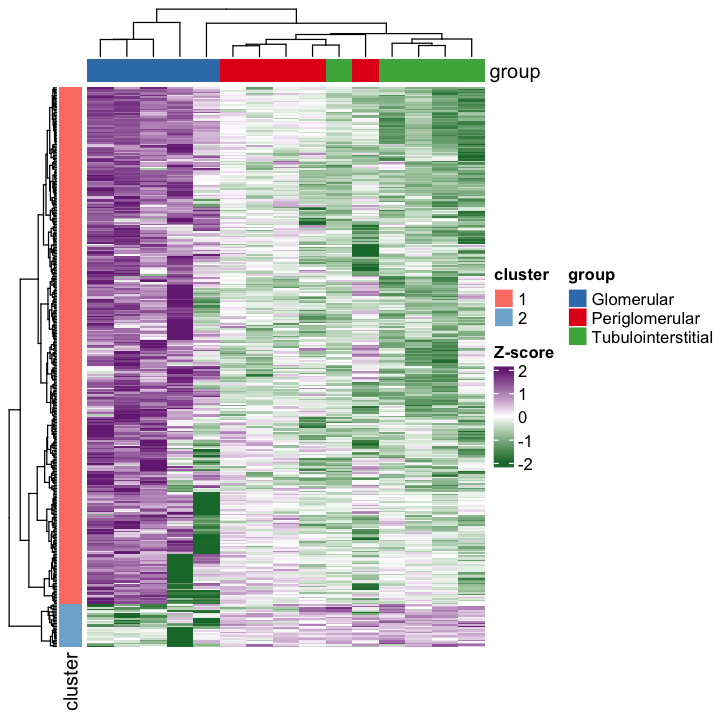

In [131]:
options(repr.plot.width = 6, repr.plot.height = 6)

# add annotation for the columns
col_anno <- HeatmapAnnotation(
  group = df_meta$group,
  col = list(group = c("Periglomerular" = "#e41a1c", 
                       "Glomerular" = "#377eb8",
                       "Tubulointerstitial" = "#4daf4a"))
)
# output clustering results for rows
cl_row <- hclust(dist(mat_z), method = "ward.D2")
cl_row_cut <- cutree(cl_row, k = 2)

# convert to data frame for annotation
df_cl_row <- data.frame(cluster = factor(cl_row_cut))
rownames(df_cl_row) <- rownames(mat_z)
# add annotation for the rows
row_anno <- rowAnnotation(
  cluster = df_cl_row$cluster,
  col = list(cluster = c("1" = "#fb8072", "2" = "#80b1d3"))
)

# set color palette for the heatmap
# use PRGn diverging palette from RColorBrewer
col_fun <- colorRamp2(c(-2, 0, 2), 
c("#1b7837", "white", "#762a83"))

Heatmap(mat_z, 
        name = "Z-score", 
        show_row_names = FALSE, 
        show_column_names = FALSE,
        cluster_rows = TRUE, 
        col = col_fun,
        clustering_method_rows = "ward.D2",
        cluster_columns = TRUE,
        clustering_method_columns = "complete",
        top_annotation = col_anno,
        left_annotation = row_anno)

In [132]:
write.csv(df_cl_row, glue::glue("{out_dir}/heatmap_row_clusters.csv"))

In [133]:
head(df_cl_row)

,cluster
,<fct>
MXRA8,1
SLC45A1,1
PDPN,1
FOXD2,1
ST6GALNAC3,1
TGFBR3,1


In [134]:
df_res1 <- df_res1[, c("log2FoldChange", "pvalue", "padj")]
df_res2 <- df_res2[, c("log2FoldChange", "pvalue", "padj")]
df_res3 <- df_res3[, c("log2FoldChange", "pvalue", "padj")]

df_res1$comparison <- "Glomerular_vs_Periglomerular"
df_res2$comparison <- "Periglomerular_vs_Tubulointerstitial"
df_res3$comparison <- "Glomerular_vs_Tubulointerstitial"

df_res1 <- df_res1[rownames(df_cl_row), ]
df_res2 <- df_res2[rownames(df_cl_row), ]
df_res3 <- df_res3[rownames(df_cl_row), ]

df_res1$cluster <- df_cl_row$cluster
df_res2$cluster <- df_cl_row$cluster
df_res3$cluster <- df_cl_row$cluster

In [135]:
df <- rbind(df_res1, df_res2, df_res3)

In [136]:
head(df)

,log2FoldChange,pvalue,padj,comparison,cluster
,<dbl>,<dbl>,<dbl>,<chr>,<fct>
MXRA8,1.097219,1.261489e-04,1.338285e-02,Glomerular_vs_Periglomerular,1
SLC45A1,1.925151,3.201514e-06,5.693987e-04,Glomerular_vs_Periglomerular,1
PDPN,1.905026,2.224854e-04,2.123634e-02,Glomerular_vs_Periglomerular,1
FOXD2,1.918431,5.692497e-06,9.430830e-04,Glomerular_vs_Periglomerular,1
ST6GALNAC3,2.134034,1.659308e-11,2.866809e-08,Glomerular_vs_Periglomerular,1
TGFBR3,1.932389,1.131863e-09,8.052204e-07,Glomerular_vs_Periglomerular,1


In [137]:
write.csv(df, glue::glue("{out_dir}/df_combined.csv"))